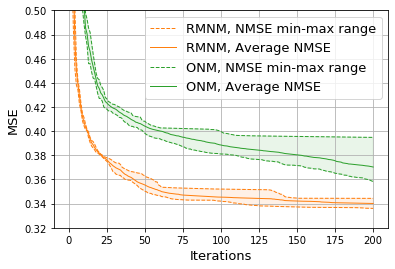

In [1]:
import os, sys

sys.path.append('../../')
from utils import plot_psd, nmse

%matplotlib inline
import matplotlib

import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# Colors visible to colorblind people
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']

# Determine experiment name and create its directory
train_size = 3341
seed_0 = 1
figure = 1
epochs = 200
exp_num = 4
chunk_num = [4, 2]
methods = ['cubic_newton_simple', 'newton_lev_marq']
# methods = ['mnm_lev_marq', 'newton_lev_marq', 'cubic_newton', 'cubic_newton_simple']
lc_train = np.zeros((len(methods), exp_num, epochs + 1))
lc_aver = np.zeros((len(methods), epochs + 1))
lc_min = np.zeros((len(methods), epochs + 1))
lc_max = np.zeros((len(methods), epochs + 1))
for j_method, method in enumerate(methods):

    for exp in range(exp_num):
        
        for chunk_num_i in chunk_num:
            exp_name = f"complex_hidden=10_std=0.1_{method}__{seed_0+exp}"
            # exp_name = f"complex_10_{method}_{2+exp}"

            add_folder = os.path.join("results_final")
            curr_path = os.getcwd()
            load_path = os.path.join(curr_path, add_folder, exp_name)

            # Plot learning curve for quality criterion
            lc_train[j_method, exp, :] = np.load(os.path.join(load_path, "lc_train_" + exp_name + ".npy"))[:epochs + 1] / train_size

    lc_aver[j_method, :] = np.mean(lc_train[j_method, :, :], axis=0)
    lc_min[j_method, :] = np.min(lc_train[j_method, :, :], axis=0)
    lc_max[j_method, :] = np.max(lc_train[j_method, :, :], axis=0)

# plt.figure(figure)
fig, ax = plt.subplots()

ax.plot(lc_min[0, :], color=colors[1], linestyle='dashed', linewidth=1)
ax.plot(lc_aver[0, :], color=colors[1], linestyle='solid', linewidth=1)
ax.plot(lc_max[0, :], color=colors[1], linestyle='dashed', linewidth=1)
plt.fill_between(np.arange(len(lc_min[0, :])), lc_min[0, :], lc_max[0, :], color=colors[1], alpha=0.1)

ax.plot(lc_min[1, :], color=colors[2], linestyle='dashed', linewidth=1)
ax.plot(lc_aver[1, :], color=colors[2], linestyle='solid', linewidth=1)
ax.plot(lc_max[1, :], color=colors[2], linestyle='dashed', linewidth=1)
plt.fill_between(np.arange(len(lc_min[1, :])), lc_min[1, :], lc_max[1, :], color=colors[2], alpha=0.1)

plt.xlabel('Iterations', fontsize=13)
plt.ylabel('MSE', fontsize=13)
plt.legend(handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1],
                    plt.gca().get_lines()[3], plt.gca().get_lines()[4]],
                    labels=['RMNM, NMSE min-max range', 'RMNM, Average NMSE', 
                            'ONM, NMSE min-max range', 'ONM, Average NMSE'], fontsize=13)

plt.ylim(0.32, 0.5)

plt.grid()

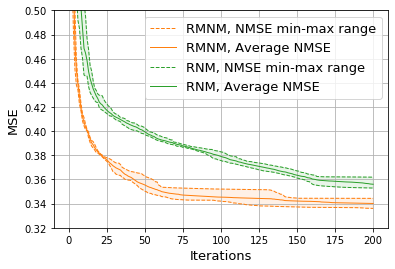

In [5]:
# Determine experiment name and create its directory
train_size = 3341
seed_0 = 1
figure = 2
epochs = 200
exp_num = 4
chunk_num = [4, 2]
methods = ['cubic_newton_simple', 'cubic_newton']
# methods = ['mnm_lev_marq', 'newton_lev_marq', 'cubic_newton', 'cubic_newton_simple']
lc_train = np.zeros((len(methods), exp_num, epochs + 1))
lc_aver = np.zeros((len(methods), epochs + 1))
lc_min = np.zeros((len(methods), epochs + 1))
lc_max = np.zeros((len(methods), epochs + 1))
for j_method, method in enumerate(methods):

    for exp in range(exp_num):
        
        for chunk_num_i in chunk_num:
            exp_name = f"complex_hidden=10_std=0.1_{method}__{seed_0+exp}"
            # exp_name = f"complex_10_{method}_{2+exp}"

            add_folder = os.path.join("results_final")
            curr_path = os.getcwd()
            load_path = os.path.join(curr_path, add_folder, exp_name)

            # Plot learning curve for quality criterion
            lc_train[j_method, exp, :] = np.load(os.path.join(load_path, "lc_train_" + exp_name + ".npy"))[:epochs + 1] / train_size

    lc_aver[j_method, :] = np.mean(lc_train[j_method, :, :], axis=0)
    lc_min[j_method, :] = np.min(lc_train[j_method, :, :], axis=0)
    lc_max[j_method, :] = np.max(lc_train[j_method, :, :], axis=0)

# plt.figure(figure)
fig, ax = plt.subplots()

ax.plot(lc_min[0, :], color=colors[1], linestyle='dashed', linewidth=1)
ax.plot(lc_aver[0, :], color=colors[1], linestyle='solid', linewidth=1)
ax.plot(lc_max[0, :], color=colors[1], linestyle='dashed', linewidth=1)
plt.fill_between(np.arange(len(lc_min[0, :])), lc_min[0, :], lc_max[0, :], color=colors[1], alpha=0.1)

ax.plot(lc_min[1, :], color=colors[2], linestyle='dashed', linewidth=1)
ax.plot(lc_aver[1, :], color=colors[2], linestyle='solid', linewidth=1)
ax.plot(lc_max[1, :], color=colors[2], linestyle='dashed', linewidth=1)
plt.fill_between(np.arange(len(lc_min[1, :])), lc_min[1, :], lc_max[1, :], color=colors[2], alpha=0.1)

plt.xlabel('Iterations', fontsize=13)
plt.ylabel('MSE', fontsize=13)
plt.legend(handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1],
                    plt.gca().get_lines()[3], plt.gca().get_lines()[4]],
                    labels=['RMNM, NMSE min-max range', 'RMNM, Average NMSE', 
                            'RNM, NMSE min-max range', 'RNM, Average NMSE'], fontsize=13)

plt.ylim(0.32, 0.5)

plt.grid()

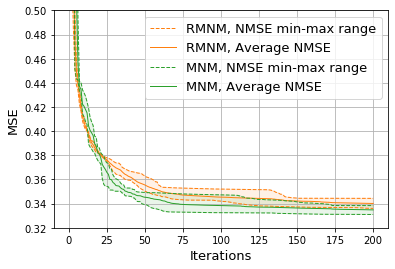

In [6]:
# Determine experiment name and create its directory
train_size = 3341
seed_0 = 1
figure = 3
epochs = 200
exp_num = 4
chunk_num = [4, 2]
methods = ['cubic_newton_simple', 'mnm_lev_marq']
# methods = ['mnm_lev_marq', 'newton_lev_marq', 'cubic_newton', 'cubic_newton_simple']
lc_train = np.zeros((len(methods), exp_num, epochs + 1))
lc_aver = np.zeros((len(methods), epochs + 1))
lc_min = np.zeros((len(methods), epochs + 1))
lc_max = np.zeros((len(methods), epochs + 1))
for j_method, method in enumerate(methods):

    for exp in range(exp_num):
        
        for chunk_num_i in chunk_num:
            exp_name = f"complex_hidden=10_std=0.1_{method}__{seed_0+exp}"
            # exp_name = f"complex_10_{method}_{2+exp}"

            add_folder = os.path.join("results_final")
            curr_path = os.getcwd()
            load_path = os.path.join(curr_path, add_folder, exp_name)

            # Plot learning curve for quality criterion
            lc_train[j_method, exp, :] = np.load(os.path.join(load_path, "lc_train_" + exp_name + ".npy"))[:epochs + 1] / train_size

    lc_aver[j_method, :] = np.mean(lc_train[j_method, :, :], axis=0)
    lc_min[j_method, :] = np.min(lc_train[j_method, :, :], axis=0)
    lc_max[j_method, :] = np.max(lc_train[j_method, :, :], axis=0)

# plt.figure(figure)
fig, ax = plt.subplots()

ax.plot(lc_min[0, :], color=colors[1], linestyle='dashed', linewidth=1)
ax.plot(lc_aver[0, :], color=colors[1], linestyle='solid', linewidth=1)
ax.plot(lc_max[0, :], color=colors[1], linestyle='dashed', linewidth=1)
plt.fill_between(np.arange(len(lc_min[0, :])), lc_min[0, :], lc_max[0, :], color=colors[1], alpha=0.1)

ax.plot(lc_min[1, :], color=colors[2], linestyle='dashed', linewidth=1)
ax.plot(lc_aver[1, :], color=colors[2], linestyle='solid', linewidth=1)
ax.plot(lc_max[1, :], color=colors[2], linestyle='dashed', linewidth=1)
plt.fill_between(np.arange(len(lc_min[1, :])), lc_min[1, :], lc_max[1, :], color=colors[2], alpha=0.1)

plt.xlabel('Iterations', fontsize=13)
plt.ylabel('MSE', fontsize=13)
plt.legend(handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1],
                    plt.gca().get_lines()[3], plt.gca().get_lines()[4]],
                    labels=['RMNM, NMSE min-max range', 'RMNM, Average NMSE', 
                            'MNM, NMSE min-max range', 'MNM, Average NMSE'], fontsize=13)

plt.ylim(0.32, 0.5)

plt.grid()

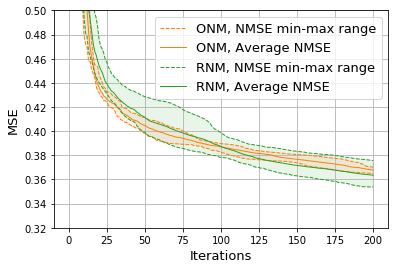

In [4]:
import os, sys

sys.path.append('../../')
from utils import plot_psd, nmse

%matplotlib inline
import matplotlib

import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# Determine experiment name and create its directory
train_size = 3341
seed_0 = 1
figure = 1
epochs = 200
exp_num = 4
chunk_num = [4, 2]
methods = ['newton_lev_marq', 'cubic_newton']
lc_train = np.zeros((len(methods), exp_num, epochs + 1))
lc_aver = np.zeros((len(methods), epochs + 1))
lc_min = np.zeros((len(methods), epochs + 1))
lc_max = np.zeros((len(methods), epochs + 1))
for j_method, method in enumerate(methods):

    for exp in range(exp_num):
        
        for chunk_num_i in chunk_num:
            exp_name = f"complex_hidden=10_std=0.1_{method}_imaginary_init_{seed_0+exp}"
            # exp_name = f"complex_10_{method}_{2+exp}"

            add_folder = os.path.join("results_final")
            curr_path = os.getcwd()
            load_path = os.path.join(curr_path, add_folder, exp_name)

            # Plot learning curve for quality criterion
            lc_train[j_method, exp, :] = np.load(os.path.join(load_path, "lc_train_" + exp_name + ".npy"))[:epochs + 1] / train_size

    lc_aver[j_method, :] = np.mean(lc_train[j_method, :, :], axis=0)
    lc_min[j_method, :] = np.min(lc_train[j_method, :, :], axis=0)
    lc_max[j_method, :] = np.max(lc_train[j_method, :, :], axis=0)

# plt.figure(figure)
fig, ax = plt.subplots()

ax.plot(lc_min[0, :], color=colors[1], linestyle='dashed', linewidth=1)
ax.plot(lc_aver[0, :], color=colors[1], linestyle='solid', linewidth=1)
ax.plot(lc_max[0, :], color=colors[1], linestyle='dashed', linewidth=1)
plt.fill_between(np.arange(len(lc_min[0, :])), lc_min[0, :], lc_max[0, :], color=colors[1], alpha=0.1)

ax.plot(lc_min[1, :], color=colors[2], linestyle='dashed', linewidth=1)
ax.plot(lc_aver[1, :], color=colors[2], linestyle='solid', linewidth=1)
ax.plot(lc_max[1, :], color=colors[2], linestyle='dashed', linewidth=1)
plt.fill_between(np.arange(len(lc_min[1, :])), lc_min[1, :], lc_max[1, :], color=colors[2], alpha=0.1)

plt.xlabel('Iterations', fontsize=13)
plt.ylabel('MSE', fontsize=13)
plt.legend(handles=[plt.gca().get_lines()[0], plt.gca().get_lines()[1],
                    plt.gca().get_lines()[3], plt.gca().get_lines()[4]],
                    labels=['ONM, NMSE min-max range', 'ONM, Average NMSE', 
                            'RNM, NMSE min-max range', 'RNM, Average NMSE'], fontsize=13)

plt.ylim(0.32, 0.5)

plt.grid()